In [4]:
import os
import numpy as np
import tensorflow as tf

d = np.load(os.path.join("data", "dataset.npz"))

def preparar(X):
    X = X.astype(np.float32) / 255.0    # uint8 0..255  ->  float32 0..1
    X = X.reshape(-1, 28, 28, 1)        # (N, 784)      ->  (N, 28, 28, 1)
    return X

X_treino = preparar(d["X_treino"])
X_val    = preparar(d["X_val"])
X_teste  = preparar(d["X_teste"])
y_treino, y_val, y_teste = d["y_treino"], d["y_val"], d["y_teste"]

for nome, X in [("treino", X_treino), ("val", X_val), ("teste", X_teste)]:
    print(f"{nome:6s} {X.shape} {X.dtype} min={X.min()} max={X.max()}")

treino (144000, 28, 28, 1) float32 min=0.0 max=1.0
val    (18000, 28, 28, 1) float32 min=0.0 max=1.0
teste  (18000, 28, 28, 1) float32 min=0.0 max=1.0


In [11]:
N_CLASSES = 15

model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    # augmentation: só atua no treino, assim como o Dropout
    tf.keras.layers.RandomRotation(0.05),         # gira até ±18°
    tf.keras.layers.RandomTranslation(0.08, 0.08), # desloca até ±8%
    tf.keras.layers.RandomZoom(0.1),               # zoom até ±10%

    # bloco 1: 28x28 -> 14x14
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # TODO bloco 2: Conv2D com 32 filtros + MaxPooling   (14x14 -> 7x7)
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    # TODO bloco 3: Conv2D com 64 filtros + MaxPooling   (7x7 -> 3x3)
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    # TODO: uma Dense com 128 neurônios e ativação relu
    tf.keras.layers.Dense(128, activation="relu"),

    # TODO: a camada de saída: Dense com N_CLASSES neurônios e ativação softmax
    tf.keras.layers.Dense(N_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 3, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,087 (387.06 KB)

 Trainable params: 99,087 (387.06 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# TODO: compile o modelo com optimizer "adam",
#       loss "sparse_categorical_crossentropy" e metrics ["accuracy"]
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

parada = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",              # TODO: qual métrica observar? (dica: veja o gráfico da direita)
    patience=3,               # quantas épocas esperar sem melhora antes de parar
    restore_best_weights=True # volta para os pesos da melhor época
)

historico = model.fit(
    # TODO: dados de treino (X e y)
    X_treino, y_treino,
    # TODO: validation_data=(..., ...)
    validation_data=(X_val, y_val),
    batch_size=128,
    epochs=30, 
    callbacks=[parada]
)


Epoch 1/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 35s 29ms/step - accuracy: 0.7912 - loss: 0.7133 - val_accuracy: 0.8902 - val_loss: 0.4133
Epoch 2/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 33s 29ms/step - accuracy: 0.8969 - loss: 0.3698 - val_accuracy: 0.9218 - val_loss: 0.3135
Epoch 3/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.9158 - loss: 0.3017 - val_accuracy: 0.9304 - val_loss: 0.2917
Epoch 4/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 44s 39ms/step - accuracy: 0.9261 - loss: 0.2665 - val_accuracy: 0.9351 - val_loss: 0.2764
Epoch 5/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 40s 35ms/step - accuracy: 0.9314 - loss: 0.2451 - val_accuracy: 0.9428 - val_loss: 0.2450
Epoch 6/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 37s 33ms/step - accuracy: 0.9363 - loss: 0.2298 - val_accuracy: 0.9457 - val_loss: 0.2315
Epoch 7/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 38s 34ms/step - accuracy: 0.9393 - loss: 0.2175 - val_accuracy: 0.9461 - val_loss: 0.2318
Epoch 8/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.9413 -

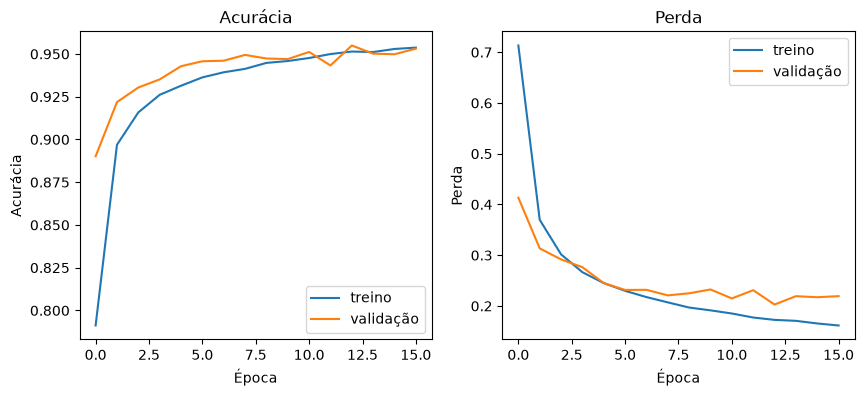

In [13]:
import matplotlib.pyplot as plt

h = historico.history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# TODO: no ax1, plote h["accuracy"] e h["val_accuracy"] (com label=... em cada um)
ax1.plot(h["accuracy"], label="treino")
ax1.plot(h["val_accuracy"], label="validação")
# TODO: no ax2, plote h["loss"] e h["val_loss"]
ax2.plot(h["loss"], label="treino")
ax2.plot(h["val_loss"], label="validação")
# dica: ax.plot(lista, label="treino"), depois ax.legend() e ax.set_title(...)

ax1.set_title("Acurácia")
ax1.set_xlabel("Época")
ax1.set_ylabel("Acurácia")
ax1.legend()

ax2.set_title("Perda")
ax2.set_xlabel("Época")
ax2.set_ylabel("Perda")
ax2.legend()

plt.show()

In [18]:
# TODO: avalie o modelo no conjunto de teste
#       dica: model.evaluate(X, y) devolve [perda, acurácia]
perda, acc = model.evaluate(X_teste, y_teste)
print(f"acurácia no teste: {acc:.2%}")

563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9532 - loss: 0.1990
acurácia no teste: 95.32%


In [20]:
CATEGORIAS = [
    "apple", "bicycle", "car", "cat", "clock",
    "eye", "fish", "house", "key", "light bulb",
    "rainbow", "star", "sun", "tree", "umbrella",
]   # mesma ordem do notebook 01!

probs = model.predict(X_teste)
print(probs.shape)   # TODO: o que significa cada dimensão?

previsto = np.argmax(probs, axis=1)       # TODO: a categoria com maior probabilidade em cada linha
print(previsto[:10])
print(y_teste[:10])

563/563 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
(18000, 15)
[ 4  4  9  3  4  2 10  2  7  0]
[ 4  4  9  3  4  2 10  2  7  0]


(15, 15)


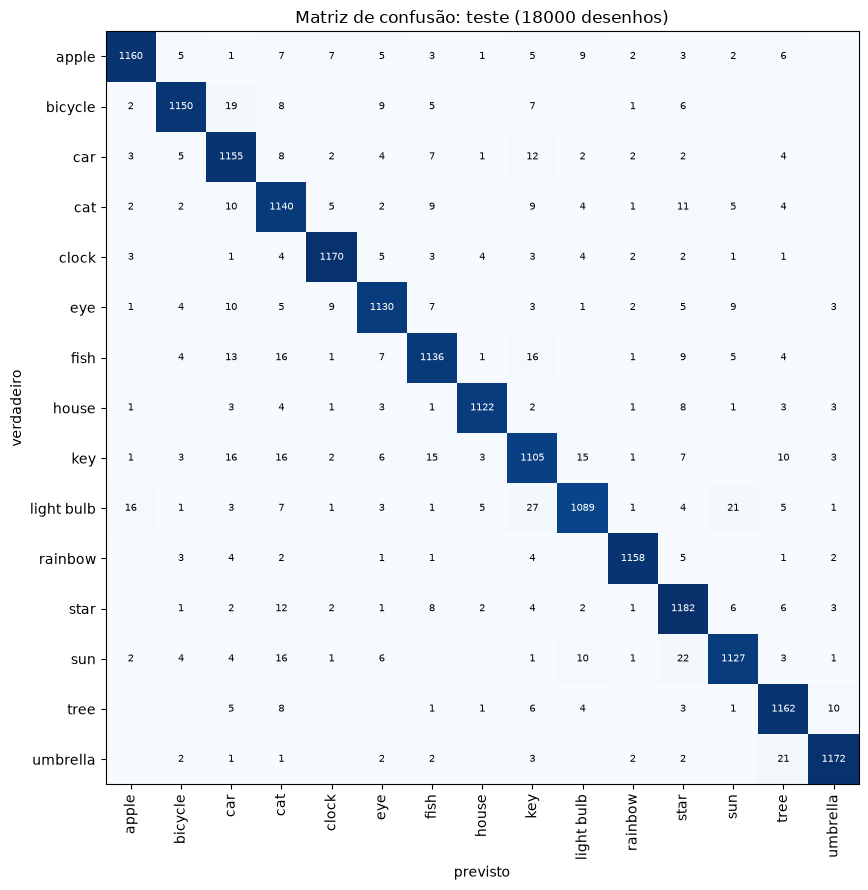

In [21]:
import matplotlib.pyplot as plt

matriz = tf.math.confusion_matrix(y_teste, previsto).numpy()
print(matriz.shape)   # (15, 15)

fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(matriz, cmap="Blues")

# nomes das categorias nos eixos
ax.set_xticks(range(len(CATEGORIAS)))
ax.set_xticklabels(CATEGORIAS, rotation=90)
ax.set_yticks(range(len(CATEGORIAS)))
ax.set_yticklabels(CATEGORIAS)

# número dentro de cada quadradinho
limite = matriz.max() / 2
for i in range(len(CATEGORIAS)):
    for j in range(len(CATEGORIAS)):
        valor = matriz[i, j]
        if valor > 0:
            cor = "white" if valor > limite else "black"   # texto claro em fundo escuro
            ax.text(j, i, valor, ha="center", va="center", fontsize=7, color=cor)

ax.set_xlabel("previsto")
ax.set_ylabel("verdadeiro")
ax.set_title(f"Matriz de confusão: teste ({len(y_teste)} desenhos)")
plt.tight_layout()
plt.show()

In [22]:
confusoes = []
for i in range(len(CATEGORIAS)):
    for j in range(len(CATEGORIAS)):
        if i != j:   # ignora a diagonal (acertos)
            confusoes.append((matriz[i, j], CATEGORIAS[i], CATEGORIAS[j]))

confusoes = sorted(confusoes, reverse=True)
for n, verdadeiro, prev in confusoes[:5]:
    print(f"{verdadeiro:10s} -> {prev:10s}: {n} vezes")

light bulb -> key       : 27 vezes
sun        -> star      : 22 vezes
umbrella   -> tree      : 21 vezes
light bulb -> sun       : 21 vezes
bicycle    -> car       : 19 vezes


In [23]:
acertos = matriz.diagonal() / matriz.sum(axis=1)
for cat, a in sorted(zip(CATEGORIAS, acertos), key=lambda t: t[1]):
    print(f"{cat:12s} {a:.1%}")

key          91.9%
light bulb   91.9%
fish         93.7%
sun          94.1%
cat          94.7%
eye          95.0%
bicycle      95.3%
apple        95.4%
car          95.7%
star         95.9%
tree         96.8%
umbrella     97.0%
clock        97.3%
house        97.3%
rainbow      98.1%


In [25]:
os.makedirs("output", exist_ok=True)
model.save(os.path.join("output", "modelo.keras"))

In [2]:
import os
import numpy as np
import tensorflow as tf

modelo_treino = tf.keras.models.load_model(os.path.join("output", "modelo.keras"))

print("camadas do modelo de treino:")
for i, camada in enumerate(modelo_treino.layers):
    print(f"  {i} {type(camada).__name__}")

# remove as camadas de augmentation (só servem no treino)
CAMADAS_DE_TREINO = (
    tf.keras.layers.RandomRotation,
    tf.keras.layers.RandomTranslation,
    tf.keras.layers.RandomZoom,
)
camadas = [c for c in modelo_treino.layers if not isinstance(c, CAMADAS_DE_TREINO)]

# entrada fixa: 1 desenho por vez, como na placa
modelo = tf.keras.Sequential([tf.keras.Input(shape=(28, 28, 1), batch_size=1)] + camadas)
modelo.summary()

camadas do modelo de treino:
  0 RandomRotation
  1 RandomTranslation
  2 RandomZoom
  3 Conv2D
  4 MaxPooling2D
  5 Conv2D
  6 MaxPooling2D
  7 Conv2D
  8 MaxPooling2D
  9 Flatten
  10 Dense
  11 Dense


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (1, 28, 28, 16)        │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (1, 14, 14, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (1, 14, 14, 32)        │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (1, 7, 7, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (1, 7, 7, 64)          │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (1, 3, 3, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (1, 576)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 128)               │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 15)                │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,087 (387.06 KB)

 Trainable params: 99,087 (387.06 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
amostra = X_teste[:20]
a = np.argmax(modelo_treino.predict(amostra, verbose=0), axis=1)
b = np.array([np.argmax(modelo.predict(x[None], verbose=0)) for x in amostra])

print("original:", a)
print("limpo:   ", b)
print("iguais?", np.array_equal(a, b))

original: [ 4  4  9  3  4  2 10  2  7  0  9 13  0 13  5  6  1  0 13  5]
limpo:    [ 4  4  9  3  4  2 10  2  7  0  9 13  0 13  5  6  1  0 13  5]
iguais? True


In [7]:
conversor = tf.lite.TFLiteConverter.from_keras_model(modelo)
tflite_float = conversor.convert()

caminho_float = os.path.join("output", "modelo_float32.tflite")
with open(caminho_float, "wb") as f:   # "wb" = escrita binária
    f.write(tflite_float)

print(f"float32: {len(tflite_float) / 1024:.1f} KB")

INFO:tensorflow:Assets written to: C:\Users\migue\AppData\Local\Temp\tmpcfof0olp\assets


INFO:tensorflow:Assets written to: C:\Users\migue\AppData\Local\Temp\tmpcfof0olp\assets


Saved artifact at 'C:\Users\migue\AppData\Local\Temp\tmpcfof0olp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 28, 28, 1), dtype=tf.float32, name='keras_tensor_156')
Output Type:
  TensorSpec(shape=(1, 15), dtype=tf.float32, name=None)
Captures:
  2294576073616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576074576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576074192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576075152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576074960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576075536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576073808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576076304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576076112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576076688: TensorSpec(shape=(), dtype=tf.resource, name=None)
float32: 3

In [8]:
def dataset_representativo():
    # 500 desenhos do treino, um por vez, para o conversor medir a faixa de valores de cada camada
    for i in range(500):
        yield [X_treino[i:i + 1]]

conversor = tf.lite.TFLiteConverter.from_keras_model(modelo)
conversor.optimizations = [tf.lite.Optimize.DEFAULT]
conversor.representative_dataset = dataset_representativo
conversor.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]  # tudo em int8
conversor.inference_input_type = tf.int8     # entrada em int8
conversor.inference_output_type = tf.int8    # saída em int8

tflite_int8 = conversor.convert()

caminho_int8 = os.path.join("output", "modelo_int8.tflite")
with open(caminho_int8, "wb") as f:
    f.write(tflite_int8)

print(f"int8:    {len(tflite_int8) / 1024:.1f} KB")
print(f"redução: {len(tflite_float) / len(tflite_int8):.1f}x")

INFO:tensorflow:Assets written to: C:\Users\migue\AppData\Local\Temp\tmp6sz9vwrd\assets


INFO:tensorflow:Assets written to: C:\Users\migue\AppData\Local\Temp\tmp6sz9vwrd\assets


Saved artifact at 'C:\Users\migue\AppData\Local\Temp\tmp6sz9vwrd'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 28, 28, 1), dtype=tf.float32, name='keras_tensor_156')
Output Type:
  TensorSpec(shape=(1, 15), dtype=tf.float32, name=None)
Captures:
  2294576073616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576074576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576074192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576075152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576074960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576075536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576073808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576076304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576076112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2294576076688: TensorSpec(shape=(), dtype=tf.resource, name=None)


c:\Users\migue\Documents\Projetos\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


int8:    108.2 KB
redução: 3.6x


In [9]:
for nome, conteudo in [("float32", tflite_float), ("int8", tflite_int8)]:
    interp = tf.lite.Interpreter(model_content=conteudo)
    entrada = interp.get_input_details()[0]
    saida = interp.get_output_details()[0]
    ops = sorted({op["op_name"] for op in interp._get_ops_details()})

    print(f"--- {nome} ---")
    print("  entrada:", entrada["shape"], entrada["dtype"].__name__, "quantização:", entrada["quantization"])
    print("  saída:  ", saida["shape"], saida["dtype"].__name__, "quantização:", saida["quantization"])
    print("  operações:", ops)

--- float32 ---
  entrada: [ 1 28 28  1] float32 quantização: (0.0, 0)
  saída:   [ 1 15] float32 quantização: (0.0, 0)
  operações: ['CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'RESHAPE', 'SOFTMAX']
--- int8 ---
  entrada: [ 1 28 28  1] int8 quantização: (0.003921568859368563, -128)
  saída:   [ 1 15] int8 quantização: (0.00390625, -128)
  operações: ['CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'RESHAPE', 'SOFTMAX']


c:\Users\migue\Documents\Projetos\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [10]:
def avaliar_tflite(conteudo, X, y):
    interp = tf.lite.Interpreter(model_content=conteudo)
    interp.allocate_tensors()
    entrada = interp.get_input_details()[0]
    saida = interp.get_output_details()[0]

    acertos = 0
    previsoes = np.empty(len(X), dtype=np.int64)
    for i in range(len(X)):
        x = X[i:i + 1]   # um desenho, shape (1, 28, 28, 1)

        # o modelo int8 precisa da entrada em int8
        if entrada["dtype"] == np.int8:
            scale, zero_point = entrada["quantization"]
            x = np.round(x / scale + zero_point)
            x = np.clip(x, -128, 127).astype(np.int8)   # garante a faixa do int8

        interp.set_tensor(entrada["index"], x)
        interp.invoke()
        resultado = interp.get_tensor(saida["index"])[0]

        previsoes[i] = np.argmax(resultado)
        acertos += int(previsoes[i] == y[i])

    return acertos / len(X), previsoes

In [11]:
acc_float, prev_float = avaliar_tflite(tflite_float, X_teste, y_teste)
acc_int8,  prev_int8  = avaliar_tflite(tflite_int8,  X_teste, y_teste)
concordam = np.mean(prev_float == prev_int8)

print(f"float32: {acc_float:.2%}")
print(f"int8:    {acc_int8:.2%}")
print(f"diferença: {(acc_int8 - acc_float) * 100:+.2f} pontos percentuais")
print(f"as duas versões dão a mesma resposta em {concordam:.2%} dos desenhos")

float32: 95.32%
int8:    95.27%
diferença: -0.05 pontos percentuais
as duas versões dão a mesma resposta em 99.72% dos desenhos
